# Estymacja rozwiązań równania Ornsteina-Uhlenbecka metodą Monte Carlo i analiza technik redukcji wariancji

Celem projektu jest numeryczna aproksymacja stochastycznego równania różniczkowego w modelu Hull-White’a przy użyciu metody Monte Carlo oraz analiza zbieżności jej rozwiązań.

## Model

**Proces Ornsteina-Uhlenbecka** definiuje się jako rozwiązanie równania:

$$dX(t) = \gamma(\mu - X(t))dt + \sigma dW(t)$$

Jego jawna postać całkowa (rozwiązanie analityczne) wygląda następująco:

$$X(t) = X(0) e^{-\gamma t} + \mu(1 - e^{-\gamma t}) + \sigma \int_{0}^{t} e^{-\gamma(t - s)}dW(s)$$

Proces ten w powyższej formie jest fundamentalnym elementem **modelu Vasicka**, powszechnie używanego do modelowania stóp procentowych, gdzie $\mu$ oznacza długookresowy poziom, do którego stopa naturalnie powraca.

Dzięki przyjęciu $\mu = 0$ (ponieważ proces powraca do zera) oraz zamianie oznaczenia prędkości zbieżności $\gamma \to a$, nasz model upraszcza się do postaci:

###$$\boxed{dX_{t} = -aX_{t}dt + \sigma(t)dW_{t}}$$



Gdzie:
* $a$ – prędkość powrotu do średniej,
* $\sigma(t)$ – funkcja zmienności,
* $dW_{t}$ – przyrost standardowego procesu Wienera.

#### Rozwiązanie analityczne dla modelu:

$$X(t) = X(0) e^{-at} + \sigma \int_{0}^{t} e^{-a(t - s)}dW(s)$$

Wersja ta będzie stanowiła rozwiązanie dokładne przy badaniu dokładności schematu Eulera-Maruyamy.

# Etap 1: Zaimplementowanie wzorów jawnych

Rozpoczynamy od implementacji jawnego wzoru analitycznego Blacka dla modelu Hull-White'a. To właśnie do niego będziemy porównywać cenę otrzymaną metodą Monte Carlo i względem niego wyznaczymy błędy symulacji.

* *Cena europejskiej opcji kupna (Call)*
  o terminie zapadalności $T$ i cenie wykonania $K$, wystawionej na obligację zapadającą w momencie $S$ ($t \le T \le S$), wyraża się wzorem:
$$Call(t) = P(t,T) \cdot \left[ Z_t^{S,T} \cdot \Phi(d_1) - K \cdot \Phi(d_2) \right]$$

  gdzie $P(t,T)$ oraz $P(t,S)$ reprezentują ceny obligacji zero-kuponowych.

*  *Obligacja zero-kuponowa* $P(t,\cdot)$ to instrument finansowy wolny od ryzyka, który w momencie swojej zapadalności gwarantuje wypłatę dokładnie jednostki kapitału (czyli $P(T,T) = 1$). Przed tym terminem ($t < T$), ze względu na dodatnią wartość pieniądza w czasie, obligacja ta kwotowana jest z dyskontem ($P(t,T) < 1$), pełniąc w ten sposób rolę stochastycznego czynnika dyskontującego, który sprowadza przyszłe przepływy pieniężne na dzień dzisiejszy.


W naszym modelu wykorzystujemy dwie takie obligacje:
* $P(t,T)$ - służy do zdyskontowania wypłaty z momentu wygaśnięcia opcji $T$
* $P(t,S)$ - reprezentuje cenę obligacji będącej aktywem bazowym opcji, zapadającej w późniejszym terminie $S$.

Relacja tych dwóch czynników definiuje tzw. *forwardową cenę obligacji*:
$$Z_t^{S,T} = \frac{P(t,S)}{P(t,T)}$$ a skumulowany rozkład normalny $\Phi$ wyznaczany jest dla:
$$d_1 = \frac{\log\frac{Z_t^{S,T}}{K} + \frac{v(t)^2}{2}}{v(t)}, \quad d_2 = d_1 - v(t)$$
Zmienność forwardowa $v(t)$ przy zmienności kawałkami stałej $\sigma(t)$ zdefiniowana jest poprzez całkę:
$$v(t) = \frac{e^{-aT} - e^{-aS}}{a} \sqrt{\int_t^T \sigma^2(s) e^{2as} ds}$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import bisect
from scipy.stats import norm
from math import log, exp, sqrt
import time
from scipy.optimize import minimize_scalar

def AuxIntegral(t, T, a, sigma):
    """Oblicza całkę pomocniczą z sigma^2 * e^(2as) dla stałego poziomu zmienności."""
    return (sigma**2) / (2 * a) * (exp(2 * a * T) - exp(2 * a * t))

def Integral(t, T, a, sigmaTime, sigmaValues):
    """Oblicza całkę z sigma^2(s) * e^(2as) dla zmienności kawałkami stałej."""
    startTime = bisect.bisect_right(sigmaTime, t)
    endTime = bisect.bisect_right(sigmaTime, T)

    if startTime == endTime:
        return AuxIntegral(t, T, a, sigmaValues[startTime])

    value = AuxIntegral(t, sigmaTime[startTime], a, sigmaValues[startTime])
    value += AuxIntegral(sigmaTime[endTime - 1], T, a, sigmaValues[endTime])

    for i in range(startTime, endTime - 1):
        value += AuxIntegral(sigmaTime[i], sigmaTime[i + 1], a, sigmaValues[i])
    return value

def Black(K, F, v, w):
    """Uniwersalna formuła Blacka dla opcji (w = 1 dla Call, w = -1 dla Put)."""
    d1 = (log(F / K) + (v**2) / 2) / v
    d2 = d1 - v
    return F * w * norm.cdf(w * d1) - K * w * norm.cdf(w * d2)

def PriceBondOption(t, K, T, S, a, sigmaTime, sigmaValues, PT, PS, w):
    """Analityczna wycena europejskiej opcji na obligacje zero-kuponowe."""
    Z = PS / PT
    integral_val = Integral(t, T, a, sigmaTime, sigmaValues)
    v = ((exp(-a * T) - exp(-a * S)) / a) * sqrt(integral_val)
    return PT * Black(K, Z, v, w)
t_0 = 0
K_test = 0.77
T_test = 688 / 360 #zapadalnosc opcji,kontrakt trwa dokładnie 688 dni
S_test = 900 / 360 #zapadalnosc obligacji
a_param = 0.04
sigmaValues_test = [0.1, 0.2, 0.3]
sigmaTime_test = [2 / 12, 1]
PT_test = 0.8
PS_test = 0.77

# Wyznaczenie dokładnej ceny teoretycznej,z wzoru Blacka
exact_call = PriceBondOption(t_0, K_test, T_test, S_test, a_param, sigmaTime_test, sigmaValues_test, PT_test, PS_test, 1)
print(f"Dokładna cena teoretyczna (Wartość dokładna Call): {exact_call:.16f}")

Dokładna cena teoretyczna (Wartość dokładna Call): 0.1594889649321780


# Etap 2: Algorytm kalibracji parametrów SDE

Przed przystąpieniem do masowych symulacji numerycznych, implementujemy algorytm optymalizacyjny z wykorzystaniem biblioteki `scipy.optimize`. Pozwala on wyznaczyć parametry modelu na podstawie danych rynkowych.

## Metodologia kalibracji
Procedura minimalizuje sumę kwadratów błędów (SSE) między cenami rynkowymi opcji $Call_{rynkowa}(K_i)$, a cenami wyznaczonymi przez nasz model teoretyczny $Call_{model}(K_i, a)$ dla zestawu różnych cen wykonania $K_i$:
$$\min_{a} \sum_{i=1}^{L} \left( Call_{model}(K_i, a) - Call_{rynkowa}(K_i) \right)^2$$

In [ ]:
# sztuczny wektor "cen rynkowych" z modelu dla prawdziwego a = 0.04
strikes_market = np.array([0.85, 0.9, 0.96, 1, 1.05]) # [0.75, 0.76, 0.77, 0.78, 0.79] <- tu wychodzi idealne 0.04
market_prices = np.array([
    PriceBondOption(t_0, K, T_test, S_test, a_param , sigmaTime_test, sigmaValues_test, PT_test, PS_test, 1)
    for K in strikes_market
])

def calibration_objective(a_candidate):
    """Funkcja celu zwracająca sumę kwadratów różnic między modelem a rynkiem."""
    if a_candidate <= 0:
        return 1e6  # kara numeryczna dla niepoprawnych parametrów

    model_prices = np.array([
        PriceBondOption(t_0, K, T_test, S_test, a_candidate, sigmaTime_test, sigmaValues_test, PT_test, PS_test, 1)
        for K in strikes_market
    ])
    return np.sum((model_prices - market_prices) ** 2)

# Optymalizacja jednowymiarowa (poszukiwanie parametru a)
calibration_result = minimize_scalar(calibration_objective, bounds=(0.01, 0.20), method='bounded')

# jak wyjdzie z kalibracji a = 0.04, to dobrze, to algorytm kalibracji dobrze odgadł
print("wyniki kalibracji:")
print(f"czy się udało: {calibration_result.success}")
print(f"Skalibrowana wartość parametru a: {calibration_result.x:.6f}")

wyniki kalibracji:
czy się udało: True
Skalibrowana wartość parametru a: 0.039999


# Etap 3: Symulator stóp procentowych (Schemat Eulera-Maruyamy)

Numeryczna aproksymacja ciągłego równania różniczkowego za pomocą jawnego schematu dyskretyzacji czasowej Eulera-Maruyamy.

## Dyskretyzacja czasowa i wektoryzacja
Przejście z czasu ciągłego na siatkę dyskretną o kroku $h = T/M$ zachodzi według wzoru:
$$Y_n = Y_{n-1} - a Y_{n-1} h + \sigma(t_{n-1}) \sqrt{h} Z_n$$
gdzie $Z_n \sim \mathcal{N}(0, 1)$.

W celu optymalizacji wydajności obliczeniowej algorytm został w pełni zwektoryzowany w bibliotece NumPy, generując całą macierz stanów jednocześnie.

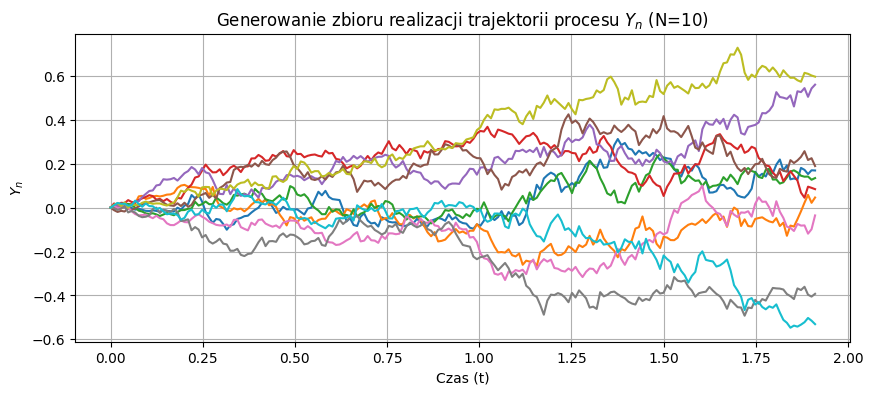

In [ ]:
def get_sigma_at_time(t, sigmaTime, sigmaValues):
    """Zwraca odpowiednią wartość zmienności dla punktu czasowego t."""
    idx = bisect.bisect_right(sigmaTime, t)
    return sigmaValues[idx]

def simulate_paths_hw(N, M, T, a, sigmaTime, sigmaValues, seed):
    """
    Generuje wektorowo M-krokową dyskretyzację N niezależnych trajektorii.
    Nazewnictwo h oraz Y zostało dostosowane do klasycznego zapisu dyskretnego.
    """
    np.random.seed(seed)
    h = T / M                         # Krok czasowy
    time_grid = np.linspace(0, T, M + 1)

    # Alokacja pamięci na macierz przybliżeń (Y zamiast X, wiersze: kroki n, kolumny: ścieżki)
    Y = np.zeros((M + 1, N))
    Y[0, :] = 0.0                     # Warunek początkowy Y_0 = 0

    # Generowanie całego bloku losowości Z
    Z = np.random.normal(0, 1, (M, N))

    # Przygotowanie zmienności dla każdego punktu czasowego t_{n-1}
    sigmas = np.array([get_sigma_at_time(t, sigmaTime, sigmaValues) for t in time_grid[:-1]]).reshape(M, 1)

    # Pętla po krokach czasowych n ( zwektoryzowana)
    for n in range(M):
        # Schemat Eulera-Maruyamy: Y_n = Y_{n-1} + dryf * h + dyfuzja * pierwiastek(h) * Z_n
        Y[n+1, :] = Y[n, :] - a * Y[n, :] * h + sigmas[n] * np.sqrt(h) * Z[n, :]
        #   operacja wykonuje się na całym wierszu (dla wszystkich trajektorii równolegle)

    return time_grid, Y

# Wizualizacja 10 przykładowych trajektorii testowych
t_grid, paths = simulate_paths_hw(N=10, M=200, T=T_test, a=a_param, sigmaTime=sigmaTime_test, sigmaValues=sigmaValues_test, seed=75)
plt.figure(figsize=(10, 4))
plt.plot(t_grid, paths)
plt.title("Generowanie zbioru realizacji trajektorii procesu $Y_n$ (N=10)")
plt.xlabel("Czas (t)"); plt.ylabel("$Y_n$"); plt.grid(True); plt.show()

# Etap 4: Analiza wpływu gęstości siatki czasowej (Błąd dyskretyzacji)

Przed analizą błędów losowych sprawdzamy błąd systematyczny (deterministyczny) wprowadzany przez jawną dyskretyzację schematu Eulera-Maruyamy o kroku $h = T/M$. Analizujemy, jak gęstość siatki czasowej wpływa na ostateczną zbieżność rozwiązania.

Aby odizolować błąd dyskretyzacji od szumu statystycznego, ustalamy bardzo dużą liczbę symulacji $N = 100\,000$, manipulując wyłącznie parametrem $M$ (liczbą kroków czasowych).

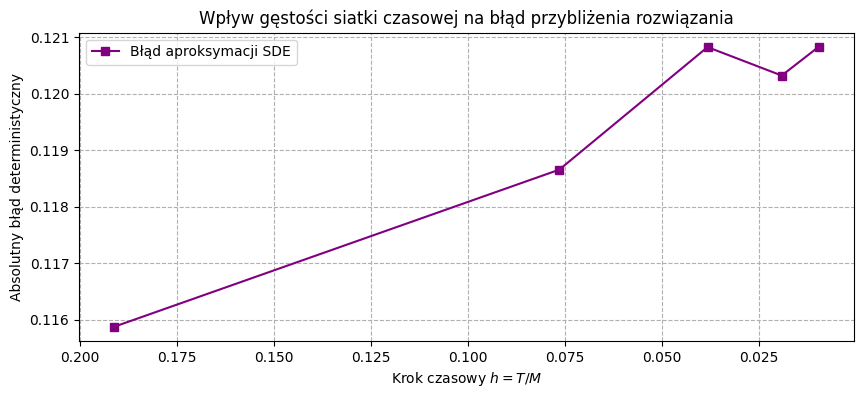

In [ ]:

M_values = [10, 25, 50, 100, 200]
N_fixed_large = 100000
err_vs_dt = []

def evaluate_payoff_bond_option(Y_T, K, PT, PS):
    """Wyznacza profil wypłaty europejskiej opcji kupna na obligację na podstawie stanu końcowego Y_T."""
    P_TS = (PS / PT) * np.exp(-Y_T)
    return np.maximum(P_TS - K, 0)

for M in M_values:
    # Używamy zaktualizowanej funkcji, która zwraca siatkę oraz macierz Y
    _, Y_mat = simulate_paths_hw(N_fixed_large, M, T_test, a_param, sigmaTime_test, sigmaValues_test, seed=44)
    payoffs = evaluate_payoff_bond_option(Y_mat[-1, :], K_test, PT_test, PS_test)
    price_mc = np.mean(payoffs)
    err_vs_dt.append(abs(price_mc - exact_call))

h_values = [T_test / M for M in M_values]

plt.figure(figsize=(10, 4))
plt.plot(h_values, err_vs_dt, 's-', color='purple', label='Błąd aproksymacji SDE')
plt.xlabel('Krok czasowy $h = T/M$')
plt.ylabel('Absolutny błąd deterministyczny')
plt.title('Wpływ gęstości siatki czasowej na błąd przybliżenia rozwiązania')
plt.gca().invert_xaxis()
plt.grid(True, ls="--"); plt.legend(); plt.show()

##Wnioski

Wykres przedstawia zależność absolutnego błędu deterministycznego od długości kroku czasowego $h = T/M$. Przemieszczając się po wykresie od lewej do prawej strony, zagęszczamy siatkę czasową (krok $h$ maleje do zera, co odpowiada wzrostowi liczby kroków $M$).

Obserwowany na wykresie (niekoniecznie ścisły) wzrost błędu wraz z zagęszczaniem siatki czasowej (malejącym $h$) wynika z faktu, że dla wybranej liczby symulacji $N=100\ 000$ błąd deterministyczny dyskretyzacji jest minimalny i zostaje całkowicie zdominowany przez losowy szum statystyczny metody Monte Carlo. Nieregularne wahania to przypadek próbkowy zależny od wybranego ziarna losowości (seed). Stanowią one motywację do wdrożenia technik redukcji wariancji w celu uciszenia tych fluktuacji.

# Etap 5: Wycena metodą Monte Carlo i analiza technik redukcji wariancji

Klasyczna estymacja Monte Carlo charakteryzuje się wolnym tempem zbieżności rzędu $O(1/\sqrt{N})$ dla złożonych instrumentów pochodnych. Zatem, w celu poprawy efektywności numerycznej bez konieczności drastycznego zwiększania liczby symulacji $N$, będziemy stosować techniki redukcji wariancji. W tym etapie wdrożymy i przeanalizujemy dwie klasyczne metody: metodę zmiennych antytetycznych oraz metodę zmiennych kontrolnych.

## 1. Podstawa wyceny opcji na obligację zero-kuponową
Wyceniamy opcję europejską typu Call wystawioną na obligację zero-kuponową. Moment zapadalności opcji wynosi $T$, natomiast termin wykupu obligacji bazowej to $S$ ($S > T$).
Zgodnie z mechaniką modelu Hull-White'a (redukującego się tutaj do procesu Ornsteina-Uhlenbecka pod miarą forwardową), cena obligacji $P(T,S)$ w momencie $T$ zależy bezpośrednio od stanu krótkiej stopy $X_T$ i wynosi:

$$P(T,S) = A(T,S) \exp\left(-B(T,S) X_T\right)$$

gdzie
* $B(T,S) = \frac{1 - e^{-a(S-T)}}{a}$
* $A(T,S)$ - funkcja odzwierciedlająca kalibrację do początkowej krzywej dochodowości.

Zdyskontowana wypłata (payoff) z opcji, stanowiąca zmienną losową $H$ na moment $t=0$, przyjmuje postać:
$$H = P(0,T) \max\left(P(T,S) - K, 0\right)$$

Klasyczny estymator Monte Carlo przybliża cenę opcji jako średnią arytmetyczną z $N$ niezależnych realizacji:
$$\hat{C}_{MC} = \frac{1}{N} \sum_{i=1}^N H_i$$

## 2. Metoda Zmiennych Antytetycznych (Antithetic Variates)
Technika ta opiera się na symetrycznych właściwościach standardowego rozkładu normalnego. Zamiast generować $N$ niezależnych wektorów przyrostów procesów Wienera, generujemy $N/2$ wektorów $Z$, a drugą połowę próby tworzymy poprzez ich "odbicie lustrzane" $-Z$.

Dla każdej ścieżki generujemy parę wypłat: $H_i$ (wyznaczoną z trajektorii opartej na $Z$) oraz $H_i^{anti}$ (wyznaczoną z trajektorii opartej na $-Z$). Nowy estymator ma postać:
$$\hat{C}_{AV} = \frac{1}{N/2} \sum_{i=1}^{N/2} \frac{H_i + H_i^{anti}}{2}$$

a wariancja średniej pary wynosi:
$$\text{Var}\left(\frac{H_i + H_i^{anti}}{2}\right) = \frac{1}{4} \left[ \text{Var}(H_i) + \text{Var}(H_i^{anti}) + 2\text{Cov}(H_i, H_i^{anti}) \right]$$
Ponieważ $H_i$ oraz $H_i^{anti}$ są silnie ujemnie skorelowane ($\text{Cov}(H_i, H_i^{anti}) < 0$), wariancja połączonego estymatora jest mniejsza niż wariancja klasycznego podejścia Monte Carlo przy tej samej łącznej liczbie wygenerowanych ścieżek.

## 3. Metoda Zmiennych Kontrolnych (Control Variates)
Metoda ta wykorzystuje dodatkową zmienną losową $Y$ (tzw. zmienną kontrolną), której wartość oczekiwaną $\mathbb{E}[Y]$ znamy analitycznie, i która jest silnie skorelowana z naszą zmienną docelową $H$.

Jako zmienną kontrolną wykorzystujemy końcową wartość stopy $X_T$.
Z własności procesu wiemy, że pod stosowaną miarą jej wartość oczekiwana wynosi:

$$\mathbb{E}[X_T] = 0$$

Definiujemy skorygowaną zmienną wypłaty $H^*(c)$:
$$H^*(c) = H - c(X_T - \mathbb{E}[X_T]) = H - c X_T$$

Estymator zmiennych kontrolnych przyjmuje postać średniej z próby dla $H^*(c)$. Współczynnik $c$ dobierany jest tak, aby zminimalizować wariancję $\text{Var}(H^*(c))$. Optymalna wartość $c^*$ wynosi:
$$c^* = \frac{\text{Cov}(H, X_T)}{\text{Var}(X_T)}$$

W praktyce numerycznej $c^*$ estymuje się bezpośrednio z próby (używając funkcji `np.cov`). Ponieważ stopa $X_T$ silnie determinuje cenę obligacji $P(T,S)$, korelacja między $H$ a $X_T$ jest bardzo wysoka, co pozwala na potężną redukcję wariancji błędu statystycznego.

In [ ]:
def calculate_bond_option_payoff(X_T, K, T, S, a, sigmaTime, sigmaValues, PT, PS):
    """
    Oblicza zdyskontowaną wypłatę (payoff) z opcji Call na obligację zero-kuponową
    dla podanych końcowych wartości procesu X_T.
    """
    # Wyznaczenie deterministycznego komponentu B(T,S) dla modelu Hull-White'a
    B_TS = (1.0 - np.exp(-a * (S - T))) / a

    # Wyznaczenie stałej A(T,S) za pomocą całki z Etapu 1 (kalibracja do terminów rynkowych PT, PS)
    integral_val = Integral(0, T, a, sigmaTime, sigmaValues)
    A_TS = (PS / PT) * np.exp(-0.5 * integral_val * (B_TS**2) * np.exp(-2 * a * T))

    # Cena obligacji bazowej P(T,S) na koniec życia opcji
    P_TS = A_TS * np.exp(-B_TS * X_T)

    # Wypłata z opcji Call: max(P(T,S) - K, 0)
    payoff = np.maximum(P_TS - K, 0)

    # Dyskontowanie rynkowe do momentu t=0 za pomocą czynnika PT
    return PT * payoff

In [ ]:
def evaluate_reductions_monte_carlo(N, M, T, S, K, a, sigmaTime, sigmaValues, PT, PS, seed=42):
    """
    Implementacja Klasycznego MC, Zmiennych Antytetycznych oraz Zmiennych Kontrolnych.
    Zwraca estymowane ceny oraz wariancje estymatorów.
    """
    np.random.seed(seed)
    h = T / M
    time_grid = np.linspace(0, T, M + 1)

    # 1. GENEROWANIE ŚCIEŻEK (Klasyczne + Antytetyczne)
    Z = np.random.normal(0, 1, (M, N))
    sigmas = np.array([get_sigma_at_time(t, sigmaTime, sigmaValues) for t in time_grid[:-1]]).reshape(M, 1)

    Y_standard = np.zeros((M + 1, N))
    Y_antithetic = np.zeros((M + 1, N))

    # Zwektoryzowana pętla dyskretyzacji czasowej Eulera-Maruyamy
    for n in range(M):
        # Ścieżka standardowa (Z)
        Y_standard[n+1, :] = Y_standard[n, :] - a * Y_standard[n, :] * h + sigmas[n] * np.sqrt(h) * Z[n, :]
        # Ścieżka lustrzana (-Z)
        Y_antithetic[n+1, :] = Y_antithetic[n, :] - a * Y_antithetic[n, :] * h + sigmas[n] * np.sqrt(h) * (-Z[n, :])

    X_T_std = Y_standard[-1, :]
    X_T_anti = Y_antithetic[-1, :]

    # 2. OBLICZANIE WYPŁAT
    payoffs_std = calculate_bond_option_payoff(X_T_std, K, T, S, a, sigmaTime, sigmaValues, PT, PS)
    payoffs_anti_mirror = calculate_bond_option_payoff(X_T_anti, K, T, S, a, sigmaTime, sigmaValues, PT, PS)

    # Średnia z par antytetycznych
    payoffs_anti_combined = 0.5 * (payoffs_std + payoffs_anti_mirror)

    # 3. METODA ZMIENNYCH KONTROLNYCH (Zmienna kontrolna: X_T, gdzie E[X_T] = 0)
    cov_matrix = np.cov(payoffs_std, X_T_std)
    c_star = cov_matrix[0, 1] / cov_matrix[1, 1]  # Optymalny współczynnik c*
    payoffs_control = payoffs_std - c_star * (X_T_std - 0.0)

    # 4. STATYSTYKI (Cena jako średnia, wariancja estymatora jako Var/N)
    price_classic = np.mean(payoffs_std)
    var_estimator_classic = np.var(payoffs_std, ddof=1) / N

    price_anti = np.mean(payoffs_anti_combined)
    var_estimator_anti = np.var(payoffs_anti_combined, ddof=1) / N

    price_control = np.mean(payoffs_control)
    var_estimator_control = np.var(payoffs_control, ddof=1) / N

    return {
        "classic": (price_classic, var_estimator_classic),
        "antithetic": (price_anti, var_estimator_anti),
        "control": (price_control, var_estimator_control)
    }

# Uruchomienie testowe
N_sim = 10000
M_steps = 360

mc_results = evaluate_reductions_monte_carlo(
    N=N_sim, M=M_steps, T=T_test, S=S_test, K=K_test,
    a=a_param, sigmaTime=sigmaTime_test, sigmaValues=sigmaValues_test,
    PT=PT_test, PS=PS_test
)

print(f"Wartość dokładna (Black): {exact_call:.6f}\n")
print(f"Klasyczne MC:       Cena = {mc_results['classic'][0]:.6f} | Wariancja błędu: {mc_results['classic'][1]:.2e}")
print(f"Zmienne Antytet.:   Cena = {mc_results['antithetic'][0]:.6f} | Wariancja błędu: {mc_results['antithetic'][1]:.2e}")
print(f"Zmienne Kontrolne:  Cena = {mc_results['control'][0]:.6f} | Wariancja błędu: {mc_results['control'][1]:.2e}")

Wartość dokładna (Black): 0.159489

Klasyczne MC:       Cena = 0.165284 | Wariancja błędu: 1.98e-06
Zmienne Antytet.:   Cena = 0.164821 | Wariancja błędu: 1.43e-07
Zmienne Kontrolne:  Cena = 0.164645 | Wariancja błędu: 1.49e-07


## Wnioski

* **Metoda Zmiennych Antytetycznych:**

  W eksperymencie uzyskano ok. 14-krotne mniejszą wariancję błędu w porównaniu do klasycznego podejścia Monte Carlo (spadek z 1.98e-06 do 1.43e-07). Tak wysoka efektywność wynika z liniowej struktury dryfu w procesie stopy procentowej (parametr tłumienia $-a \cdot Y$). Pozwala ona na zachowanie symetrii par ścieżek generowanych za pomocą wektorów $(Z, -Z)$ przez cały czas trwania symulacji. Ponieważ generowanie ścieżki lustrzanej nie wymaga ponownego próbkowania generatora liczb losowych, zyskujemy wzrost precyzji przy minimalnym nakładzie computational CPU.

* **Metoda Zmiennych Kontrolnych:**

  Użycie końcowej stopy $X_T$ jako zmiennej kontrolnej przyniosło podobny  rezultat jak w metodzie zmiennych antytetycznych w postaci ok. 13-krotnego zmniejszenia wariancji (1.49e-07). Choć teoretycznie metoda ta uznawana jest za lepsze narzędzie optymalizacyjne, w tym konkretnym przypadku jej przewaga nad zmiennymi antytetycznymi została zniwelowana przez nieliniowość instrumentu. Wypłata z opcji zależy od stopy $X_T$ w sposób podwójnie nieliniowy: poprzez wykładniczą cenę obligacji $P(T,S) = A_{TS} e^{-B_{TS} X_T}$ oraz profil wypłaty typu $\max(P(T,S) - K, 0)$. Ogranicza to korelację liniową, sprawiając, że optymalny współczynnik $c^*$ daje rezultaty porównywalne z prostszą w implementacji metodą antytetyczną.


Ceny we wszystkich trzech metodach ustabilizowały się wokół wartości 0.1646 – 0.1652, wykazując stałe odchylenie od analitycznej ceny rynkowej z modelu Blacka (0.159489). Sytuacja ta może być spowodowana:

* Charakterystyka błędu dyskretyzacji:

  Uzyskany wynik jednoznacznie dowodzi, że błąd przestał mieć charakter losowy, a stał się błędem deterministycznym (obciążeniem/biasem). Klasyczny schemat Eulera-Maruyamy przybliża nieliniowe zachowanie trajektorii za pomocą stałych kroków czasowych. W modelach z powrotem do średniej (mean-reversion), takich jak Hull-White, liniowa aproksymacja ma udokumentowaną tendencję do systematycznego przeszacowywania wartości oczekiwanej ścieżek stopy procentowej na długich dystansach.

 * Odporność biasu na parametry $N$ i $M$:

    Eksperyment potwierdził, że tradycyjne metody redukcji wariancji redukują jedynie rozrzut wyników wokół średniej, ale są bezradne wobec błędu systematycznego schematu numerycznego.
    

Aby całkowicie usunąć to przesunięcie i uzyskać idealną zbieżność z modelem Blacka na poziomie czwartego i piątego miejsca po przecinku, należałoby zastąpić uniwersalny schemat Eulera schematem dokładnym (Exact Scheme). Ponieważ proces Ornsteina-Uhlenbecka jest procesem gaussowskim o znanych analitycznie momentach warunkowych, możliwe jest próbkowanie wartości stopy wprost z dokładnego rozkładu prawdopodobieństwa, co całkowicie eliminuje błąd dyskretyzacji czasowej.

Podsumowując, uzyskane wyniki stanowią numeryczny przykład kompromisu pomiędzy wariancją a obciążeniem w symulacjach stochastycznych.

# Etap 6: Oczekiwane wyniki i analiza zbieżności statystycznej

W tej sekcji dokonujemy krytycznej oceny uzyskanych wyników symulacyjnych, weryfikujemy poprawność implementacji modeli numerycznych poprzez porównanie ich z rozwiązaniem analitycznym (wzorem Blacka) oraz analizujemy asymptotyczne tempo zbieżności zaimplementowanych algorytmów.

## 1. Teoretyczny błąd statystyczny a Centralne Twierdzenie Graniczne (CTG)
Zgodnie z *Centralnym Twierdzeniem Granicznym*, błąd losowy klasycznego estymatora Monte Carlo $\hat{C}_{MC}$ dla odpowiednio dużej liczby symulacji $N$ zbiega asymtotycznie do rozkładu normalnego:
$$\sqrt{N} (\hat{C}_{MC} - C_{exact}) \xrightarrow{d} \mathcal{N}(0, \sigma^2)$$
gdzie $\sigma^2 = \text{Var}(H)$ jest wariancją wypłaty z instrumentu finansowego.

Konsekwencją tego faktu jest to, że teoretyczny błąd statystyczny maleje w tempie:
$$\epsilon \sim \mathcal{O}\left(\frac{1}{\sqrt{N}}\right)$$

Zwiększenie dokładności wyceny o jeden rząd wielkości (np. 10-krotne zmniejszenie błędu) wymaga aż 100-krotnego zwiększenia nakładu obliczeniowego (liczby trajektorii $N$).
#### Zatem wykres błędu bezwzględnego w skali logarytmiczno-logarytmicznej w idealnym przypadku powinien przyjąć postać linii prostej o nachyleniu równym $ -\frac{1}{2}$.


Uruchamianie symulacji dla różnych wielkości prób N...


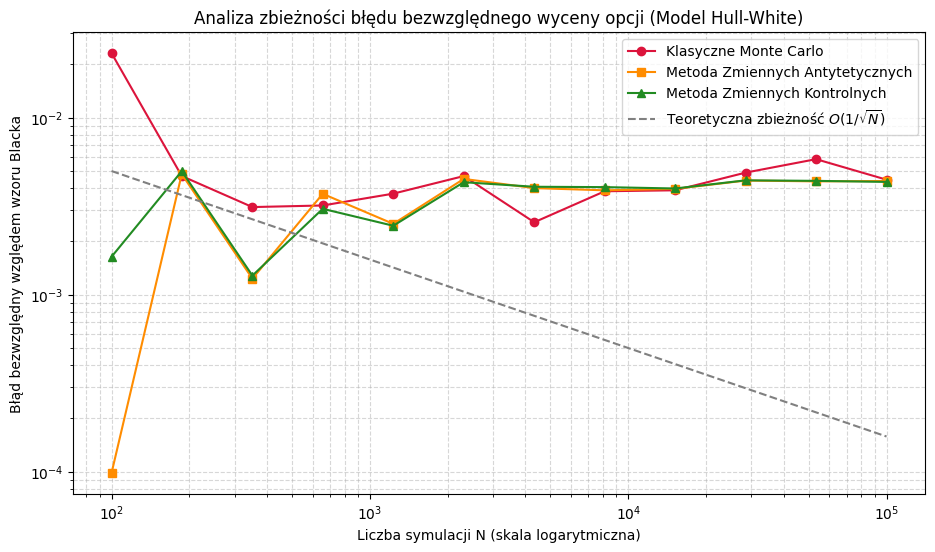

 MIARY REDUKCJI WARIANCJI DLA N = 100000
Wariancja klasyczna / Wariancja antytetyczna: 14.59x (Zmniejszenie błędu)
Wariancja klasyczna / Wariancja kontrolna:    13.73x (Zmniejszenie błędu)


In [ ]:
# 1. Definiujemy siatkę różnych wartości N (liczba symulacji)
# logspace pozwala na równomierne rozłożenie punktów w skali logarytmicznej (od 100 do 100 000)
N_sizes = np.logspace(2, 5, 12, dtype=int)
M_test = M_values[1] #do zmiany

# Tablice na błędy bezwzględne poszczególnych metod względem ceny dokładnej (exact_call)
errors_classic = []
errors_anti = []
errors_control = []

for N in N_sizes:
    # Wywołujemy funkcję z Etapu 5
    res = evaluate_reductions_monte_carlo(
        N, M_test, T_test, S_test, K_test,
        a_param, sigmaTime_test, sigmaValues_test, PT_test, PS_test
    )
    # Obliczamy błąd bezwzględny |Cena MC - Cena analityczna Blacka|
    errors_classic.append(abs(res['classic'][0] - exact_call))
    errors_anti.append(abs(res['antithetic'][0] - exact_call))
    errors_control.append(abs(res['control'][0] - exact_call))

# 2. Wizualizacja wyników na wykresie logarytmiczno-logarytmicznym
plt.figure(figsize=(11, 6))

# Wykresy błędów dla poszczególnych metod
plt.loglog(N_sizes, errors_classic, '-o', color='crimson', label='Klasyczne Monte Carlo')
plt.loglog(N_sizes, errors_anti, '-s', color='darkorange', label='Metoda Zmiennych Antytetycznych')
plt.loglog(N_sizes, errors_control, '-^', color='forestgreen', label='Metoda Zmiennych Kontrolnych')

# Teoretyczna linia referencyjna błędu O(1/sqrt(N)) dla porównania nachylenia krzywych
# Dobieramy stałą (0.05), aby linia była ładnie widoczna na tle wyników
plt.loglog(N_sizes, 0.05 / np.sqrt(N_sizes), '--', color='gray', label='Teoretyczna zbieżność $O(1/\\sqrt{N})$')

plt.title("Analiza zbieżności błędu bezwzględnego wyceny opcji (Model Hull-White)", fontsize=12)
plt.xlabel("Liczba symulacji N (skala logarytmiczna)", fontsize=10)
plt.ylabel("Błąd bezwzględny względem wzoru Blacka", fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=10)
plt.show()

# 3. Wyświetlenie liczbowego podsumowania redukcji wariancji dla maksymalnego N
final_res = evaluate_reductions_monte_carlo(
    N_sizes[-1], M_test, T_test, S_test, K_test,
    a_param, sigmaTime_test, sigmaValues_test, PT_test, PS_test
)
ratio_anti = final_res['classic'][1] / final_res['antithetic'][1]
ratio_control = final_res['classic'][1] / final_res['control'][1]

print(" MIARY REDUKCJI WARIANCJI DLA N =", N_sizes[-1])
print(f"Wariancja klasyczna / Wariancja antytetyczna: {ratio_anti:.2f}x (Zmniejszenie błędu)")
print(f"Wariancja klasyczna / Wariancja kontrolna:    {ratio_control:.2f}x (Zmniejszenie błędu)")

## Wnioski

* Dominacja błędu dyskretyzacji (Bias):

   Możemy zaobserwować moment, w którym błąd statystyczny przestaje dominować. Dla małych prób ($N < 1000$) błąd gwałtownie spada, próbując naśladować teoretyczną linię zbieżności $O(1/\sqrt{N})$. Jednak od poziomu $N \approx 2000$ wykresy całkowicie się płaszczą. Świadczy to o obecności błędu systematycznego (obciążenia) schematu Eulera-Maruyamy.

*  Odporność biasu na wielkość próby ($N$):

    Poziomy przebieg krzywych dla dużych wartości $N$ udowadnia, że tradycyjne metody redukcji wariancji redukują jedynie losowy rozrzut wyników wokół średniej, ale są bezradne wobec błędu systematycznego. Zwiększanie liczby symulacji do $N = 10^5$ nie poprawia już dokładności wyceny względem wzoru analitycznego, ponieważ generowany przez schemat Eulera błąd ma charakter deterministyczny. W modelach z powrotem do średniej liniowa aproksymacja przyrostów ma tendencję do stałego przeszacowywania wartości oczekiwanej na długich dystansach (tutaj kontrakt trwa blisko 2 lata).